# Problem 3.5

Consider the residual equation

$$r(u) = u^3 - 6u^2 + 12u - 8 = 0.$$

a. Find the solution using your own implementation of Newton's method.

b. Tabulate the residual for each iteration number.

c. What is the lowest error you can achieve?

d. Plot the residual versus the iteration number using a linear axis. How many digits can you discern in this plot?

e. Make the same plot using a logarithmic axis for the residual and estimate the rate of convergence. Discuss whether the rate is as expected or not.

f. *Exploration:* Try different starting points. Can you find a predictable trend and explain it?

In [118]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [119]:
# a) solve with own implementation of Newton's method
# b) tabulate residual for each iteration

# implementation adapted from prob 3_3
def residual(u):
    return u**3 - 6*u**2 + 12*u - 8

def derrivatie(u):
    return 3*u**2 - 12*u + 12

def solve_system(u0, max_iter=30, tol=1e-7, table=True):
    u = u0
    history = []                        # (iteration, u, residual)
    converged = False
    for i in range(max_iter):
        r = residual(u)
        history.append((i, u, r))       # update the history
        if abs(r) <= tol:               # converged when the residual is small
            converged = True            # stop iterating when r is below the tolerance
            break
        u = u - r / derrivatie(u)       # calculate u_k+1 for the next iteration

    if table:
        print(f"{'iter':>4} {'u':>14} {'r':>14}")
        for i_k, u_k, r_k in history:
            print(f"{i_k:4d} {u_k:14.8f} {r_k:14.8f}")
    else:
        print(f"u: {u:.8f}, r: {residual(u):.8f}")
    print(f"{'converged' if converged else 'NOT converged'} after {i} iterations")
    return u, history

# c) lowest error when directly starting at the solution
solve_system(2.0, table=True);

iter              u              r
   0     2.00000000     0.00000000
converged after 0 iterations


In [120]:
# a run with a normal starting point
u1, history = solve_system(-15.0, table=True);

iter              u              r
   0   -15.00000000 -4913.00000000
   1    -9.33333333 -1455.70370370
   2    -5.55555556  -431.31961591
   3    -3.03703704  -127.79840471
   4    -1.35802469   -37.86619399
   5    -0.23868313   -11.21961303
   6     0.50754458    -3.32432979
   7     1.00502972    -0.98498660
   8     1.33668648    -0.29184788
   9     1.55779099    -0.08647345
  10     1.70519399    -0.02562176
  11     1.80346266    -0.00759163
  12     1.86897511    -0.00224937
  13     1.91265007    -0.00066648
  14     1.94176671    -0.00019748
  15     1.96117781    -0.00005851
  16     1.97411854    -0.00001734
  17     1.98274569    -0.00000514
  18     1.98849713    -0.00000152
  19     1.99233142    -0.00000045
  20     1.99488761    -0.00000013
  21     1.99659174    -0.00000004
converged after 21 iterations


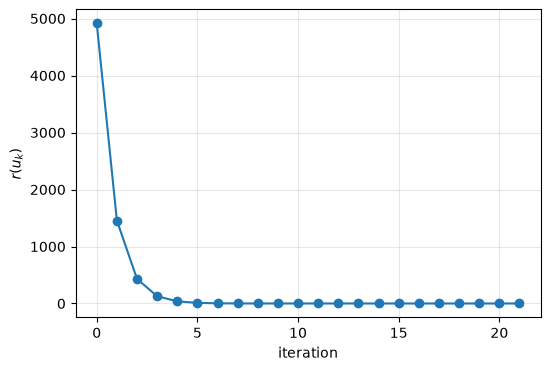

In [121]:
# d) plotting the residual on a linear scale
iters = [h[0] for h in history]
res = [np.abs(h[2]) for h in history] # plotting the absolute value of the residual to avoid negative values

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(iters, res, "o-")
ax.set_xlabel("iteration")
ax.set_ylabel("$r(u_k)$")
ax.grid(alpha=0.3)
plt.show()

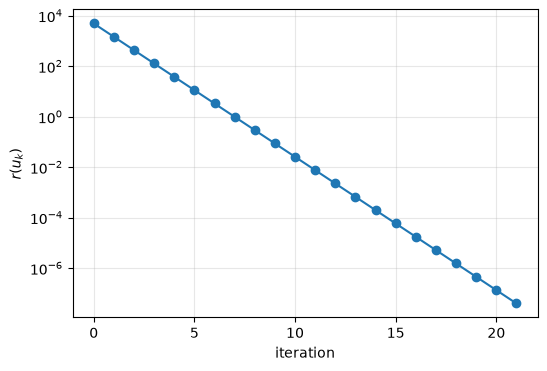

In [122]:
# d) plotting the residual on a log scale
iters = [h[0] for h in history]
res = [np.abs(h[2]) for h in history]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(iters, res, "o-")
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("$r(u_k)$")
ax.grid(alpha=0.3)
plt.show()

d) dicerning the number of digits in the plot & e) discussion of convergece rate  

on the linear plot its very difficutlt to make out differences after the fifth iteration. any residual lower than 10 will be difficult for a human to read. on the log plot the trend is much clearer to see. the convergence is very much linear on the plot. also from reading the residuals themselves we can see that the solver reduces the residuals by one order of magnitude every two iterations. in the book it states that the convergence for newtons method is quadratic (p.68). so the behaivor of the solver here is not quite expected. this may be because residual is very "flat" around zero. so the derrivatives near the solution are very small so the solver has trouble converging. this is also stated in the book. from my reading the current solver/residual combination has p=1, gamma ~ 0,3

u: 2.00388101, r: 0.00000006
converged after 25 iterations
u: 2.00360874, r: 0.00000005
converged after 19 iterations
u: 2.00456732, r: 0.00000010
converged after 16 iterations
u: 2.00342549, r: 0.00000004
converged after 14 iterations
u: 1.99657451, r: -0.00000004
converged after 14 iterations
u: 1.99543268, r: -0.00000010
converged after 15 iterations
u: 1.99594016, r: -0.00000007
converged after 17 iterations
u: 1.99684235, r: -0.00000003
converged after 19 iterations
u: 1.99639126, r: -0.00000005
converged after 20 iterations


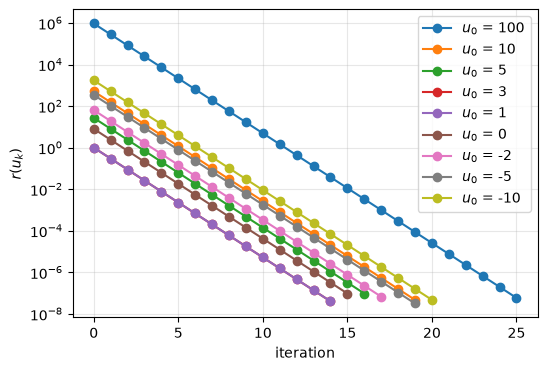

In [123]:
# f) exploration
starts = [100.0, 10.0, 5.0, 3.0, 1.0, 0.0, -2.0, -5.0, -10.0]
fig, ax = plt.subplots(figsize=(6, 4))
for u0 in starts:
    _, history = solve_system(u0, table=False)
    iters = [h[0] for h in history]
    res = [np.abs(h[2]) for h in history]
    ax.plot(iters, res, "o-", label=f"$u_0$ = {u0:g}")

ax.set_xlabel("iteration")
ax.set_ylabel("$r(u_k)$")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


f) identifying trends  
the convergence rate does not change when variing the starting point. the jumps of the residual each iteration is constant (in the log plot)

## Results

see above

## Interpretation

the choice and scaling of the residual matters to the convergence behavior of the solver. newton solvers are bad with low residuals near the solution and thus take longer to converge. in this case the residual has a saddlepoint a the solution and thus the derrivative near the solution is also small. these factors slow down the convergence.